# Predictive MissForest validation for transformer imputation

**S6-A01 · Sprint 6 · Subteam A · Rishank Goyal**

The parent ticket consolidates the anchor, feature and rules, and grouped-gap analyses. MissForest is strong on scattered gaps, with **0.656** mean numeric skill, and loses substantial signal when related fields are withheld together, falling to **0.264**.

**Run this notebook.** Use a Python 3 Jupyter kernel with pandas and Matplotlib, then run all cells. The tables and figures use embedded extracts of the saved benchmark scores. They reproduce the analysis from those scores.

## Validation scope

Predictive MissForest fits target-wise forests on measured training data and reuses those trees to fill evaluation rows. This Sprint 6 review recomputes evidence from the saved synthetic transformer benchmark. It uses the nine crossed generator–split pairs, ±5% measurement noise, and the model-only arm unless the comparison explicitly uses exact rules first. The benchmark uses spatial holdouts and evaluates hidden entries against clean reference values.

Mean numeric skill averages the 13 target skills within each pair and then across pairs. The placebo and Model ID are excluded from that aggregate. Field breaks use the independently pooled errors and loose-tolerance counts.

In [1]:
%matplotlib inline
from io import StringIO
from math import isclose
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd

PAIR = ["generator_seed", "split_seed"]
FIELD = {
    "x": "x", "y": "y", "install_date": "Installation day", "model_id": "Model ID",
    "altitude": "Altitude", "measured_humid": "Humidity", "measured_salt": "Salt",
    "measured_overgrowth": "Overgrowth", "life": "Life", "random_placebo": "Placebo",
    "measured_gas_a": "Gas A", "measured_gas_b": "Gas B", "measured_gas_c": "Gas C",
    "total_gas": "Total gas", "leakage": "Leakage",
}
TEAL, NAVY, RUST, MUTE = "#087973", "#203e53", "#a3452a", "#647783"
plt.rcParams.update({
    "figure.dpi": 140, "font.size": 10, "axes.spines.top": False,
    "axes.spines.right": False, "axes.labelcolor": NAVY,
    "axes.titlecolor": NAVY, "axes.axisbelow": True, "grid.alpha": 0.22,
})

In [2]:
# Archived score extract. Rows and columns are restricted to this analysis.
anchor_arms = pd.read_csv(StringIO("""
generator_seed,split_seed,model_without_correction,model_with_correction,rules_without_correction,rules_with_correction
219,617,0.6642341630541152,0.6596825490762511,0.6582516767134371,0.6574661465786835
219,631,0.6608413113918605,0.6571734366552107,0.6643964536132834,0.6616410912938983
219,653,0.6762915704986026,0.6757834428651043,0.6902337421604657,0.687558698559858
220,617,0.648656961862767,0.6447390835743599,0.6671955985809694,0.6647607749363135
220,631,0.6492004161908569,0.6479006784508734,0.6390887356977939,0.6398668071742381
220,653,0.6442835041295262,0.6469302627325839,0.6456980079626903,0.6487402887119809
221,617,0.663351161771389,0.6634616074595393,0.6482789447032163,0.6502701500389256
221,631,0.657066562078171,0.654266810658674,0.6436746825913235,0.6443711715808755
221,653,0.6468787822696609,0.6521064775801411,0.6542374392864106,0.6529169131933055
"""))

In [3]:
# Archived score extract. Rows and columns are restricted to this analysis.
paired_conditions = pd.read_csv(StringIO("""
condition,generator_seed,split_seed,skill
Grouped,219,617,0.2755248213479068
Grouped,219,631,0.2563168212889032
Grouped,219,653,0.1757245886826091
Grouped,220,617,0.337398037480489
Grouped,220,631,0.2384181700958085
Grouped,220,653,0.2619334958519207
Grouped,221,617,0.2762571580563727
Grouped,221,631,0.2454686392177116
Grouped,221,653,0.3049992842069593
Scattered,219,617,0.6596825490762511
Scattered,219,631,0.6571734366552107
Scattered,219,653,0.6757834428651042
Scattered,220,617,0.6447390835743599
Scattered,220,631,0.6479006784508734
Scattered,220,653,0.6469302627325837
Scattered,221,617,0.6634616074595393
Scattered,221,631,0.654266810658674
Scattered,221,653,0.6521064775801411
"""))

In [4]:
# Archived score extract. Rows and columns are restricted to this analysis.
field_totals = pd.read_csv(StringIO("""
condition,attribute,n,absolute_error_sum,floor_absolute_error_sum,within_loose_n
Grouped,altitude,5290,289195.8610432722,173462,214
Grouped,install_date,5403,596423.6197725541,1852814,3211
Grouped,leakage,5385,480.2937595437956,536.1723491720184,3211
Grouped,life,5296,668791.5952957277,1513073.038285659,5070
Grouped,measured_gas_a,5281,2494294.323421053,6561147.097304152,4472
Grouped,measured_gas_b,5281,2045534.504286202,5645243.993918253,4658
Grouped,measured_gas_c,5281,2160780.7321731,5070121.959095811,4580
Grouped,measured_humid,5399,877.889888402729,938.4355165999679,1008
Grouped,measured_overgrowth,5399,1504.863602842511,1593.494755886614,319
Grouped,measured_salt,5399,1167.430703611696,1128.530418745932,851
Grouped,total_gas,5281,1945648.206083485,5599666.657255469,5060
Grouped,x,5290,31772.33737154427,131345,3793
Grouped,y,5290,212235.245559185,135631,266
Scattered,altitude,5458,70187.55537526976,179380,1776
Scattered,install_date,5403,205881.6359496211,1852814,3755
Scattered,leakage,5385,472.3903335875537,536.1723491720184,3232
Scattered,life,5296,496001.4234108286,1513073.038285659,5209
Scattered,measured_gas_a,5281,1034400.26778517,6561147.097304152,5137
Scattered,measured_gas_b,5454,1082433.986410651,5825926.362990587,5304
Scattered,measured_gas_c,5444,968597.6835967695,5208151.908488499,5329
Scattered,measured_humid,5399,395.0013727928319,938.4355165999679,2490
Scattered,measured_overgrowth,5326,509.9330304350053,1600.181509060026,1770
Scattered,measured_salt,5360,725.9619163130886,1124.471506385375,1809
Scattered,total_gas,5360,1354558.163276643,5817174.502253948,5347
Scattered,x,5290,14970.52995334891,131345,4325
Scattered,y,5415,68099.34340680009,136718,1822
"""))

In [5]:
# Archived score extract. Rows and columns are restricted to this analysis.
rule_evidence = pd.read_csv(StringIO("""
generator_seed,split_seed,attribute,hidden_n,direct_n,remaining_n,direct_rules_mae,remaining_model_mae,remaining_rules_mae,direct_skill_delta,remaining_skill_delta
219,617,altitude,597,279,318,0,18.8901704829867,32.2026987167598,0.0733743632604338,-0.2026124235828393
219,631,altitude,638,316,322,0,20.49120255268228,32.43942625050889,0.07801522375400299,-0.1692025697378912
219,653,altitude,593,277,316,0,14.65389177572592,22.39162015093116,0.1128856148738163,-0.1396733786453132
220,617,altitude,609,300,309,0,19.90235892164814,29.46274465551702,0.0781401831114428,-0.1393405590191729
220,631,altitude,606,298,308,0,23.02035890878596,41.31145133639021,0.0967431780604138,-0.2785491454982503
220,653,altitude,600,288,312,0,16.23025352393902,29.117633362571,0.1167686832899966,-0.2272444054285734
221,617,altitude,617,309,308,0,20.53477712707082,44.18690203806774,0.09142087070207899,-0.3358004274263414
221,631,altitude,613,300,313,0,21.07118893852502,44.36776898244051,0.0898531441768546,-0.3503497599454931
221,653,altitude,585,278,307,0,16.82794420777458,28.54134677285059,0.105062883344089,-0.2164318138717023
"""))

In [6]:
# Archived score extract. Rows and columns are restricted to this analysis.
altitude_scores = pd.read_csv(StringIO("""
generator_seed,split_seed,arm,skill
219,617,model,0.6391232813461627
219,617,rules,0.5098852210237573
219,631,model,0.6318023845684664
219,631,rules,0.5406150385845782
219,653,model,0.6225976593676213
219,653,rules,0.5958098955961244
220,617,model,0.6317872303695593
220,617,rules,0.5705868544618291
220,631,model,0.5526872029578271
220,631,rules,0.3708812355199907
220,653,model,0.5970416987904277
220,653,rules,0.4865659766518508
221,617,model,0.6170371658454541
221,617,rules,0.3726576091211919
221,631,model,0.5932640355781864
221,631,rules,0.3327674198095479
221,653,model,0.5840024869967598
221,653,rules,0.4726335564691465
"""))

## Scattered and grouped performance

In [7]:
scores = paired_conditions.pivot(index=PAIR, columns="condition", values="skill")
scores = scores[["Scattered", "Grouped"]]
assert len(scores) == 9 and scores.notna().all().all()
assert tuple(scores.mean().round(3)) == (0.656, 0.264)

field_totals["pooled_skill"] = 1 - field_totals.absolute_error_sum / field_totals.floor_absolute_error_sum
field_totals["within_loose"] = field_totals.within_loose_n / field_totals.n
field_totals["breaks"] = field_totals.pooled_skill.lt(0.10) | field_totals.within_loose.lt(0.50)
field_totals["below_floor"] = field_totals.pooled_skill.lt(0)
result = field_totals.groupby("condition")[["breaks", "below_floor"]].sum()
result["Mean numeric skill"] = scores.mean()
result = result.loc[["Scattered", "Grouped"]].rename(columns={
    "breaks": "Fields that break", "below_floor": "Fields below floor",
})
display(result.style.format({"Mean numeric skill": "{:.3f}"}))
below = field_totals.loc[field_totals.condition.eq("Grouped") & field_totals.below_floor, "attribute"]
assert set(below) == {"y", "altitude", "measured_salt"}
display(field_totals.loc[field_totals.condition.eq("Grouped") & field_totals.below_floor,
                         ["attribute", "pooled_skill", "within_loose"]].assign(
    attribute=lambda frame: frame.attribute.map(FIELD)
).set_index("attribute").style.format({"pooled_skill": "{:.3f}", "within_loose": "{:.1%}"}))

,Fields that break,Fields below floor,Mean numeric skill
condition,,,
Scattered,5,0,0.656
Grouped,5,3,0.264


,pooled_skill,within_loose
attribute,,
Altitude,-0.667,4.0%
Salt,-0.034,15.8%
y,-0.565,5.0%


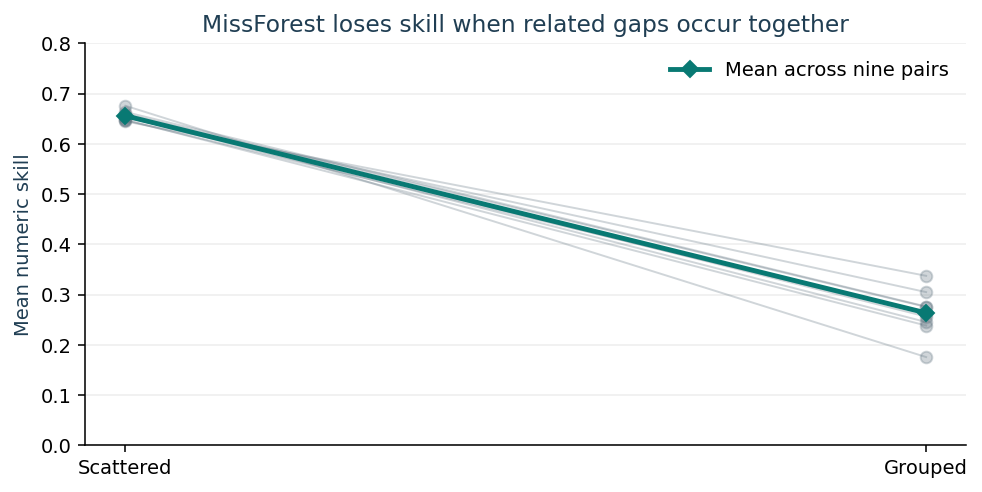

In [8]:
fig, ax = plt.subplots(figsize=(6.9, 3.4), layout="constrained")
for _, row in scores.iterrows():
    ax.plot(scores.columns, row, color=MUTE, marker="o", alpha=0.3, linewidth=1)
ax.plot(scores.columns, scores.mean(), color=TEAL, marker="D", linewidth=2.5, label="Mean across nine pairs")
ax.set(title="MissForest loses skill when related gaps occur together",
       ylabel="Mean numeric skill", ylim=(0, 0.8))
ax.grid(axis="y")
ax.legend(frameon=False)
plt.show()

## Feature and rules audit

In [9]:
def altitude_residual_summary(rule_rows):
    """Summarize model error on the same altitude cells left for the forest."""
    altitude = rule_rows.loc[rule_rows.attribute.eq("altitude")]
    remaining = altitude.remaining_n.sum()
    return pd.Series({
        "Exact altitude fills": altitude.direct_n.sum(),
        "Remaining altitude gaps": remaining,
        "Model-only MAE on remaining gaps":
            (altitude.remaining_model_mae * altitude.remaining_n).sum() / remaining,
        "Rules-first MAE on remaining gaps":
            (altitude.remaining_rules_mae * altitude.remaining_n).sum() / remaining,
    })

residual = altitude_residual_summary(rule_evidence)
assert residual["Remaining altitude gaps"] == 2813
assert residual["Exact altitude fills"] == 2645
assert round(residual["Model-only MAE on remaining gaps"], 1) == 19.1
assert round(residual["Rules-first MAE on remaining gaps"], 1) == 33.7

In [10]:
without = anchor_arms.model_without_correction.mean()
with_correction = anchor_arms.model_with_correction.mean()
rules_first = anchor_arms.rules_with_correction.mean()
by_arm = altitude_scores.groupby("arm").skill.mean()
feature_table = pd.DataFrame({
    "Model only without correction": [without],
    "Model only with correction": [with_correction],
    "Rules first with correction": [rules_first],
}, index=["Anchor mean numeric skill"])
display(feature_table.style.format(precision=3))
display(pd.DataFrame({
    "Altitude skill on all gaps": [by_arm["model"], by_arm["rules"]],
    "Altitude MAE on remaining gaps": [
        residual["Model-only MAE on remaining gaps"], residual["Rules-first MAE on remaining gaps"]
    ],
}, index=["Model only", "Rules first"]).style.format({
    "Altitude skill on all gaps": "{:.3f}", "Altitude MAE on remaining gaps": "{:.1f}",
}))

,Model only without correction,Model only with correction,Rules first with correction
Anchor mean numeric skill,0.657,0.656,0.656


,Altitude skill on all gaps,Altitude MAE on remaining gaps
Model only,0.608,19.1
Rules first,0.472,33.7


## Ticket conclusions

- **A01.1** MissForest has strong anchor gas and life scores. The placebo is near the floor.
- **A01.2** The decay correction changes mean anchor skill by about −0.001. Rules fill 2,645 altitude gaps exactly, while error rises on the 2,813 remaining gaps. The cause of the residual deterioration remains unresolved.
- **A01.3** The grouped stress test retains the same five field breaks while y, altitude, and salt fall below the median floor. The count alone misses that deterioration.

The evidence supports using MissForest as a scattered-gap benchmark where helpers remain visible. Field-level error and missing-pattern validation matter before model-based fills are used in an asset register.

## Subticket attachments

- [A01.1 Anchor review](A01_1_MissForest_Anchor.ipynb)
- [A01.2 Feature and rules audit](A01_2_MissForest_Features_and_Rules.ipynb)
- [A01.3 Grouped-gap analysis](A01_3_MissForest_Grouped_Gaps.ipynb)

## Sources and reproducibility

Paths are relative to the original Subteam A run archive. Hash prefixes identify the archived files. The embedded extracts allow the calculations above to run in a fresh notebook session. Use the repository’s setup and benchmark instructions to reproduce the source runs with the Team 19 data.

| Archived source | Evidence used | SHA-256 prefix |
| --- | --- | --- |
| final/tables/cells.csv | Anchor field scores and pair aggregates | 9d8119486d0cbae0 |
| final/tables/macro_run_scores.csv | Paired feature and rules settings at the anchor | 280b4303444c8d02 |
| final/tables/rule_effects.csv | Remaining altitude gaps and their matched errors | 811032c8cc7acbc3 |
| anchor-stress/tables/cells.csv | Grouped field scores and pair aggregates | f4b3c14586d8bf47 |

[Sections 6, 8A, and 10 of the capstone report](https://github.com/alienblack/SAPN_endtoend/blob/6ae6621/docs/Final_Report.pdf) · [Source code and reproduction guide](https://github.com/alienblack/SAPN_endtoend)